In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Link direto do dataset
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

# Carregando
df = pd.read_csv(url)
print("Dimensões do Dataset:", df.shape)
print(df['Class'].value_counts(normalize=True))

Dimensões do Dataset: (284807, 31)
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Padronizando
scaler = StandardScaler()
df['Amount'] = scaler.fit_transform(df[['Amount']])
df['Time'] = scaler.fit_transform(df[['Time']])

# Separando X e y
X = df.drop('Class', axis=1)
y = df['Class']

# Split estratificado para manter a proporção de fraudes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc, confusion_matrix

def avaliar_modelo(modelo, X_test, y_test, nome_modelo):
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    print(f"--- {nome_modelo} ---")
    print(classification_report(y_test, y_pred))

    # ROC AUC
    roc_auc = roc_auc_score(y_test, y_prob)
    print(f"ROC AUC: {roc_auc:.4f}")

    # Precision-Recall AUC
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(recall, precision)
    print(f"PR AUC: {pr_auc:.4f}\n")

# 1. Regressão Logística com peso balanceado
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
avaliar_modelo(lr, X_test, y_test, "Regressão Logística")

# 2. Random Forest com peso balanceado
rf = RandomForestClassifier(class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
avaliar_modelo(rf, X_test, y_test, "Random Forest")

# 3. XGBoost (ajustando scale_pos_weight para o desbalanceamento)
# scale_pos_weight = (número de negativos) / (número de positivos)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')
xgb.fit(X_train, y_train)
avaliar_modelo(xgb, X_test, y_test, "XGBoost")

--- Regressão Logística ---
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     85295
           1       0.07      0.88      0.12       148

    accuracy                           0.98     85443
   macro avg       0.53      0.93      0.56     85443
weighted avg       1.00      0.98      0.99     85443

ROC AUC: 0.9680
PR AUC: 0.7406

--- Random Forest ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.97      0.70      0.82       148

    accuracy                           1.00     85443
   macro avg       0.99      0.85      0.91     85443
weighted avg       1.00      1.00      1.00     85443

ROC AUC: 0.9275
PR AUC: 0.8152

--- XGBoost ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.89      0.78      0.83       148

    accuracy                           1.00     8544

Avaliação com Threshold = 0.3
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.87      0.78      0.83       148

    accuracy                           1.00     85443
   macro avg       0.94      0.89      0.91     85443
weighted avg       1.00      1.00      1.00     85443



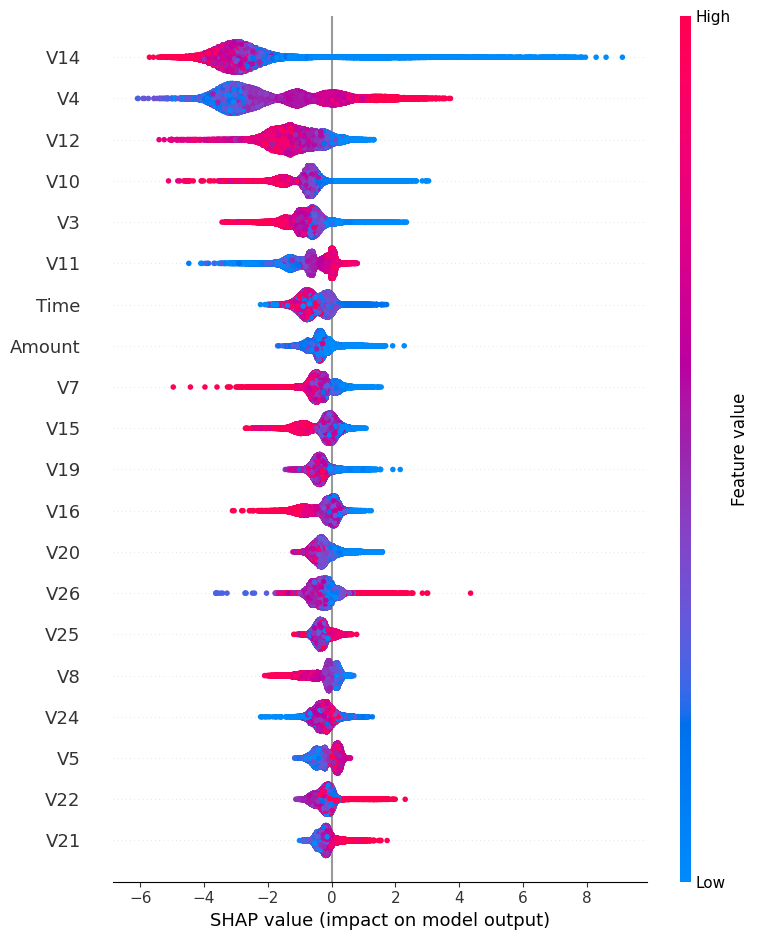

In [4]:
# Ajuste de limiar com o XGBoost (ou o modelo que teve melhor resultado)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]
threshold = 0.3
y_pred_custom = (y_prob_xgb >= threshold).astype(int)

print(f"Avaliação com Threshold = {threshold}")
print(classification_report(y_test, y_pred_custom))

# Explicabilidade com SHAP
import shap
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)

# Plotando o gráfico de resumo (Summary Plot)
shap.summary_plot(shap_values, X_test)